# Video frame sampling
We take frames from training videos at fixed time intervals and frames keep their original size

In [5]:
from pathlib import Path
import csv
import math
import time
import cv2
import matplotlib.pyplot as plt

dataset_path = Path("../../Nexar_DashCam_Dataset")
output_dir = dataset_path.parent / "sampled_frames"
sample_fps = 2
videos_per_class = 5  # Use None to select all training videos.

# Choose videos
We sort the videos and select the same number from each class

In [6]:
positive_videos = sorted((dataset_path / "train" / "positive").glob("*.mp4"))
negative_videos = sorted((dataset_path / "train" / "negative").glob("*.mp4"))
pilot_videos = positive_videos[:videos_per_class] + negative_videos[:videos_per_class]
print(f"Selected: {len(pilot_videos)} videos")

Selected: 10 videos


# Save frames
We take frames from each video at a fixed rate and save them in a separate folder

We also save the frame details in a CSV file


In [7]:
def save_sampled_frames(video_path, output_dir, sample_fps=2):
    rate_dir = output_dir / f"{sample_fps:g}fps"
    video_dir = rate_dir / video_path.parent.name / video_path.stem
    if video_dir.exists():
        raise FileExistsError(f"Output already exists: {video_dir}")
    capture = cv2.VideoCapture(str(video_path))
    if not capture.isOpened():
        raise ValueError(f"Couldnt open video: {video_path}")
    source_fps = capture.get(cv2.CAP_PROP_FPS)
    expected_frames = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
    if not math.isfinite(source_fps) or source_fps <= 0 or sample_fps > source_fps:
        capture.release()
        raise ValueError(f"Invalid video or sampling FPS: {video_path}")
    video_dir.mkdir(parents=True)
    rows = []
    frame_index = 0
    start = time.perf_counter()
    try:
        while True:
            success, frame = capture.read()
            if not success:
                break
            timestamp = frame_index / source_fps
            if timestamp + 1e-9 >= len(rows) / sample_fps:
                frame_path = video_dir / f"{frame_index:06d}.jpg"
                if not cv2.imwrite(str(frame_path), frame):
                    raise OSError(f"Could not save {frame_path}")
                rows.append({"video_id": video_path.stem, "frame_index": frame_index,
                             "timestamp_sec": round(timestamp, 6),
                             "frame_path": frame_path.relative_to(rate_dir).as_posix(),
                             "video_label": int(video_path.parent.name == "positive")})
            frame_index += 1
    finally:
        capture.release()
    if not rows or (expected_frames > 0 and frame_index < expected_frames):
        raise ValueError(f"Incomplete video: {video_path} ({frame_index}/{expected_frames})")
    with (video_dir / "frames.csv").open("w", encoding="utf-8", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=rows[0].keys())
        writer.writeheader()
        writer.writerows(rows)
    summary = {"frame_count": len(rows), "source_fps": source_fps,
               "processing_seconds": time.perf_counter() - start,
               "frame_bytes": sum(p.stat().st_size for p in video_dir.glob("*.jpg"))}
    return summary, rows

# Run sampling
Only the selected videos are processed and existing folders are not overwritten

In [12]:
results = []
errors = []
for video in pilot_videos:
    try:
        summary, rows = save_sampled_frames(video, output_dir, sample_fps)
        results.append((video, summary, rows))
        print(f"{video.name}: {len(rows)} frames, {summary['processing_seconds']:.2f} s")
    except (OSError, ValueError, cv2.error) as error:
        errors.append((video.name, str(error)))
        print(f"FAILED {video.name}: {error}")
print(f"\nCompleted: {len(results)}/{len(pilot_videos)}; failed: {len(errors)}")

00000.mp4: 81 frames, 2.26 s
00003.mp4: 81 frames, 2.31 s
00004.mp4: 81 frames, 3.13 s
00005.mp4: 81 frames, 3.05 s
00006.mp4: 80 frames, 3.14 s
01040.mp4: 79 frames, 2.87 s
01041.mp4: 79 frames, 2.96 s
01042.mp4: 36 frames, 1.35 s
01043.mp4: 81 frames, 2.96 s
01045.mp4: 81 frames, 2.66 s

Completed: 10/10; failed: 0


## Check frames

We show four frames from one positive and one negative video. For positive videos, we also check how close a saved frame is to the event time. The event time is not used to select frames.


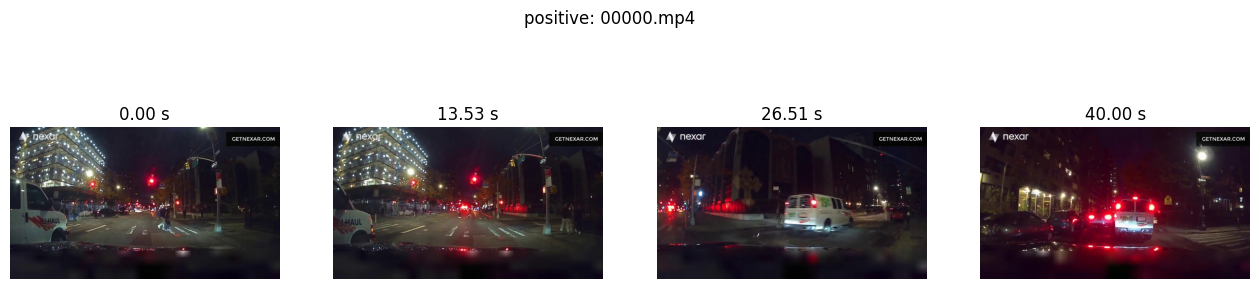

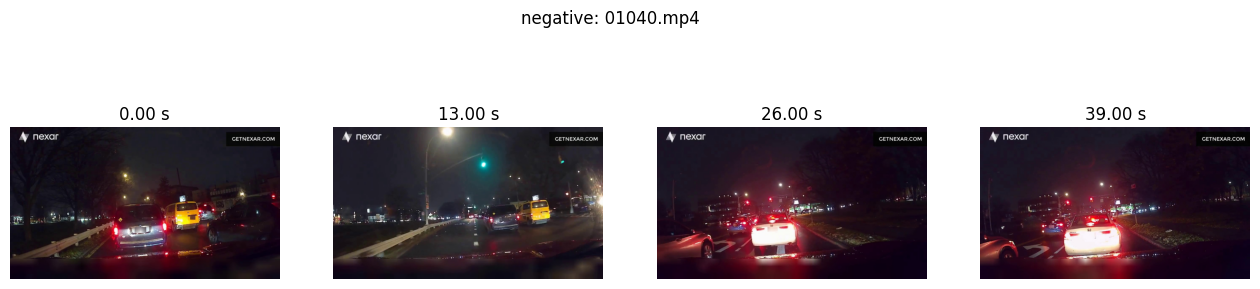

00000.mp4: event 20.76 s, nearest sampled frame 0.241 s away
00003.mp4: event 19.23 s, nearest sampled frame 0.233 s away
00004.mp4: event 19.37 s, nearest sampled frame 0.133 s away
00005.mp4: event 20.87 s, nearest sampled frame 0.139 s away
00006.mp4: event 19.23 s, nearest sampled frame 0.233 s away


In [13]:
rate_dir = output_dir / f"{sample_fps:g}fps"
for class_name in ("positive", "negative"):
    examples = [(v, s, r) for v, s, r in results if v.parent.name == class_name]
    if not examples:
        print(f"No completed {class_name} video to display.")
        continue
    video, _, rows = examples[0]
    chosen = [rows[round(i * (len(rows) - 1) / 3)] for i in range(4)]
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    for ax, row in zip(axes, chosen):
        frame = cv2.imread(str(rate_dir / row["frame_path"]))
        if frame is None:
            raise ValueError(f"Could not read {row['frame_path']}")
        ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{float(row['timestamp_sec']):.2f} s")
        ax.axis("off")
    fig.suptitle(f"{class_name}: {video.name}")
    plt.show()
with (dataset_path / "train" / "positive" / "metadata.csv").open(encoding="utf-8-sig", newline="") as file:
    events = {row["file_name"]: row["time_of_event"] for row in csv.DictReader(file)}
for video, _, rows in results:
    if video.parent.name == "positive" and events.get(video.name):
        event = float(events[video.name])
        distance = min(abs(float(row["timestamp_sec"]) - event) for row in rows)
        print(f"{video.name}: event {event:.2f} s, nearest sampled frame {distance:.3f} s away")


# Results: 10 videos
We tested 1, 2, and 4 FPS on five positive and five negative videos

The times below are from an earlier local run and may change on another run

| Sampling rate | Total frames | Average frames per video | Average time per video | JPEG size |
|---|---:|---:|---:|---:|
| 1 FPS | 384 | 38.4 | 1.59 s | 67.87 MiB |
| 2 FPS | 760 | 76.0 | 2.59 s | 134.22 MiB |
| 4 FPS | 1515 | 151.5 | 2.03 s | 267.70 MiB |

We use 2 FPS as the starting point 

We have not trained a model yet, so we dont know which rate gives the best predictions
---